# Cohort retention analysis

Do customers come back after their first purchase, and how does that differ by cohort?

**Method.** Customers are grouped into monthly cohorts by the month of their **first
recognised order**. `month_offset` counts whole months from that cohort month, so offset 0 is
the acquisition month by construction and month-0 retention is always 100% of the cohort. A
customer counts as retained in an offset month when they place at least one recognised order
in it.

**Fixed analysis end date.** Recency and observability use the last order date of the loaded
window (`2026-09-30`), never the wall clock. Offsets beyond that date are not observable and
are left blank in the matrix rather than reported as zero retention.

**Revenue definition.** Recognised net merchandise revenue (completed orders only).

In [1]:
import pandas as pd
from IPython.display import Image, display

from novacart.analytics.common import load_analysis_inputs
from novacart.analytics.cohorts import cohort_analysis, validate_retention
from novacart.analytics.plots import (
    FIGURE_FILENAMES,
    plot_cohort_retention_heatmap,
    plot_cohort_revenue_curve,
    plot_cohort_sizes,
    save_figure,
)

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

## 1. Build the cohorts

In [2]:
inputs = load_analysis_inputs()
analysis_end_date = inputs.window["analysis_end_date"].iloc[0]
print(f"analysis end date       : {analysis_end_date:%Y-%m-%d}")

cohorts = cohort_analysis(inputs.orders, analysis_end_date=analysis_end_date)
validate_retention(cohorts.retention, cohorts.sizes)
print(f"cohorts                 : {len(cohorts.sizes):,}")
print(f"customers in cohorts    : {int(cohorts.sizes['cohort_size'].sum()):,}")
print(f"retention rows          : {len(cohorts.retention):,}")

cohorts.sizes.head(8)

analysis end date       : 2026-09-30
cohorts                 : 24
customers in cohorts    : 7,622
retention rows          : 300


,cohort_index,cohort_month,cohort_size,months_observed,total_revenue,revenue_per_customer,repeat_customers,repeat_customer_rate
0,0,2024-10-01,847,24,5921497.32,6991.14,800,0.9445
1,1,2024-11-01,615,23,2301639.79,3742.50,518,0.8423
2,2,2024-12-01,336,22,779297.60,2319.34,245,0.7292
3,3,2025-01-01,202,21,403114.74,1995.62,142,0.7030
4,4,2025-02-01,184,20,379074.78,2060.19,135,0.7337
5,5,2025-03-01,201,19,360896.22,1795.50,125,0.6219
6,6,2025-04-01,200,18,380821.37,1904.11,137,0.6850
7,7,2025-05-01,254,17,337373.91,1328.24,156,0.6142


## 2. Retention matrix

Rows are cohorts, columns are months since first purchase. Every row starts at 100% and
never exceeds it; blank cells are months that are not yet observable.

In [3]:
matrix = cohorts.retention_matrix.copy()
matrix.index = [timestamp.strftime("%Y-%m") for timestamp in matrix.index]
(matrix * 100).round(1)

month_offset,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
2024-10,100.0,73.2,70.4,57.1,53.6,59.5,60.3,62.3,61.2,67.5,69.2,65.3,68.7,74.5,76.3,60.4,63.9,68.6,66.2,64.7,71.9,68.2,69.4,69.3
2024-11,100.0,43.6,34.6,33.8,35.0,35.1,39.5,38.9,41.5,41.3,38.4,44.1,47.3,48.9,36.9,35.8,44.4,41.3,42.1,49.1,42.6,46.5,41.9,NaN
2024-12,100.0,22.6,23.8,22.9,21.4,22.6,24.4,25.3,28.0,25.3,27.1,32.1,33.0,25.3,25.0,30.6,25.3,25.0,30.6,29.5,25.9,29.5,NaN,NaN
2025-01,100.0,16.3,19.3,20.3,18.8,21.3,26.7,23.3,26.2,20.3,27.7,24.8,18.3,21.3,25.7,23.3,25.2,28.2,19.8,24.8,24.3,NaN,NaN,NaN
2025-02,100.0,24.5,19.0,23.9,19.6,23.9,26.6,22.3,27.7,33.7,29.4,21.2,23.4,28.3,23.9,23.9,32.1,24.5,26.1,24.5,NaN,NaN,NaN,NaN
2025-03,100.0,18.9,18.9,18.9,22.4,22.9,22.4,21.9,26.4,23.9,22.4,18.4,21.9,21.9,25.4,26.9,25.4,23.4,21.4,NaN,NaN,NaN,NaN,NaN
2025-04,100.0,23.5,22.5,21.5,26.0,19.0,23.0,28.5,25.5,24.0,24.0,23.5,23.0,21.0,26.5,25.5,26.0,25.0,NaN,NaN,NaN,NaN,NaN,NaN
2025-05,100.0,22.4,19.7,17.3,19.7,18.9,22.8,22.8,16.9,19.7,21.3,21.6,18.1,23.6,19.3,20.9,23.6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-06,100.0,16.5,19.6,21.4,20.5,24.6,25.9,17.4,18.8,21.4,21.0,19.2,22.8,19.6,19.6,23.2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-07,100.0,19.4,22.9,22.0,22.9,25.6,19.4,22.5,23.4,25.6,17.6,22.5,20.7,19.8,24.7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
latest = cohorts.retention_matrix
month_one = cohorts.retention.loc[cohorts.retention["month_offset"] == 1, "retention_rate"]
month_three = cohorts.retention.loc[cohorts.retention["month_offset"] == 3, "retention_rate"]
print(f"median month-1 retention: {month_one.median():.1%} across {len(month_one)} cohorts")
print(f"median month-3 retention: {month_three.median():.1%} across {len(month_three)} cohorts")
print(f"matrix shape            : {latest.shape[0]} cohorts x {latest.shape[1]} month offsets")
print(f"month-0 rows equal 100% : {bool((latest[0].round(10) == 1.0).all())}")
print(f"rates above 100%        : {int((latest > 1.0).sum().sum())}")

median month-1 retention: 21.3% across 23 cohorts
median month-3 retention: 21.4% across 21 cohorts
matrix shape            : 24 cohorts x 24 month offsets
month-0 rows equal 100% : True
rates above 100%        : 0


## 3. Figures

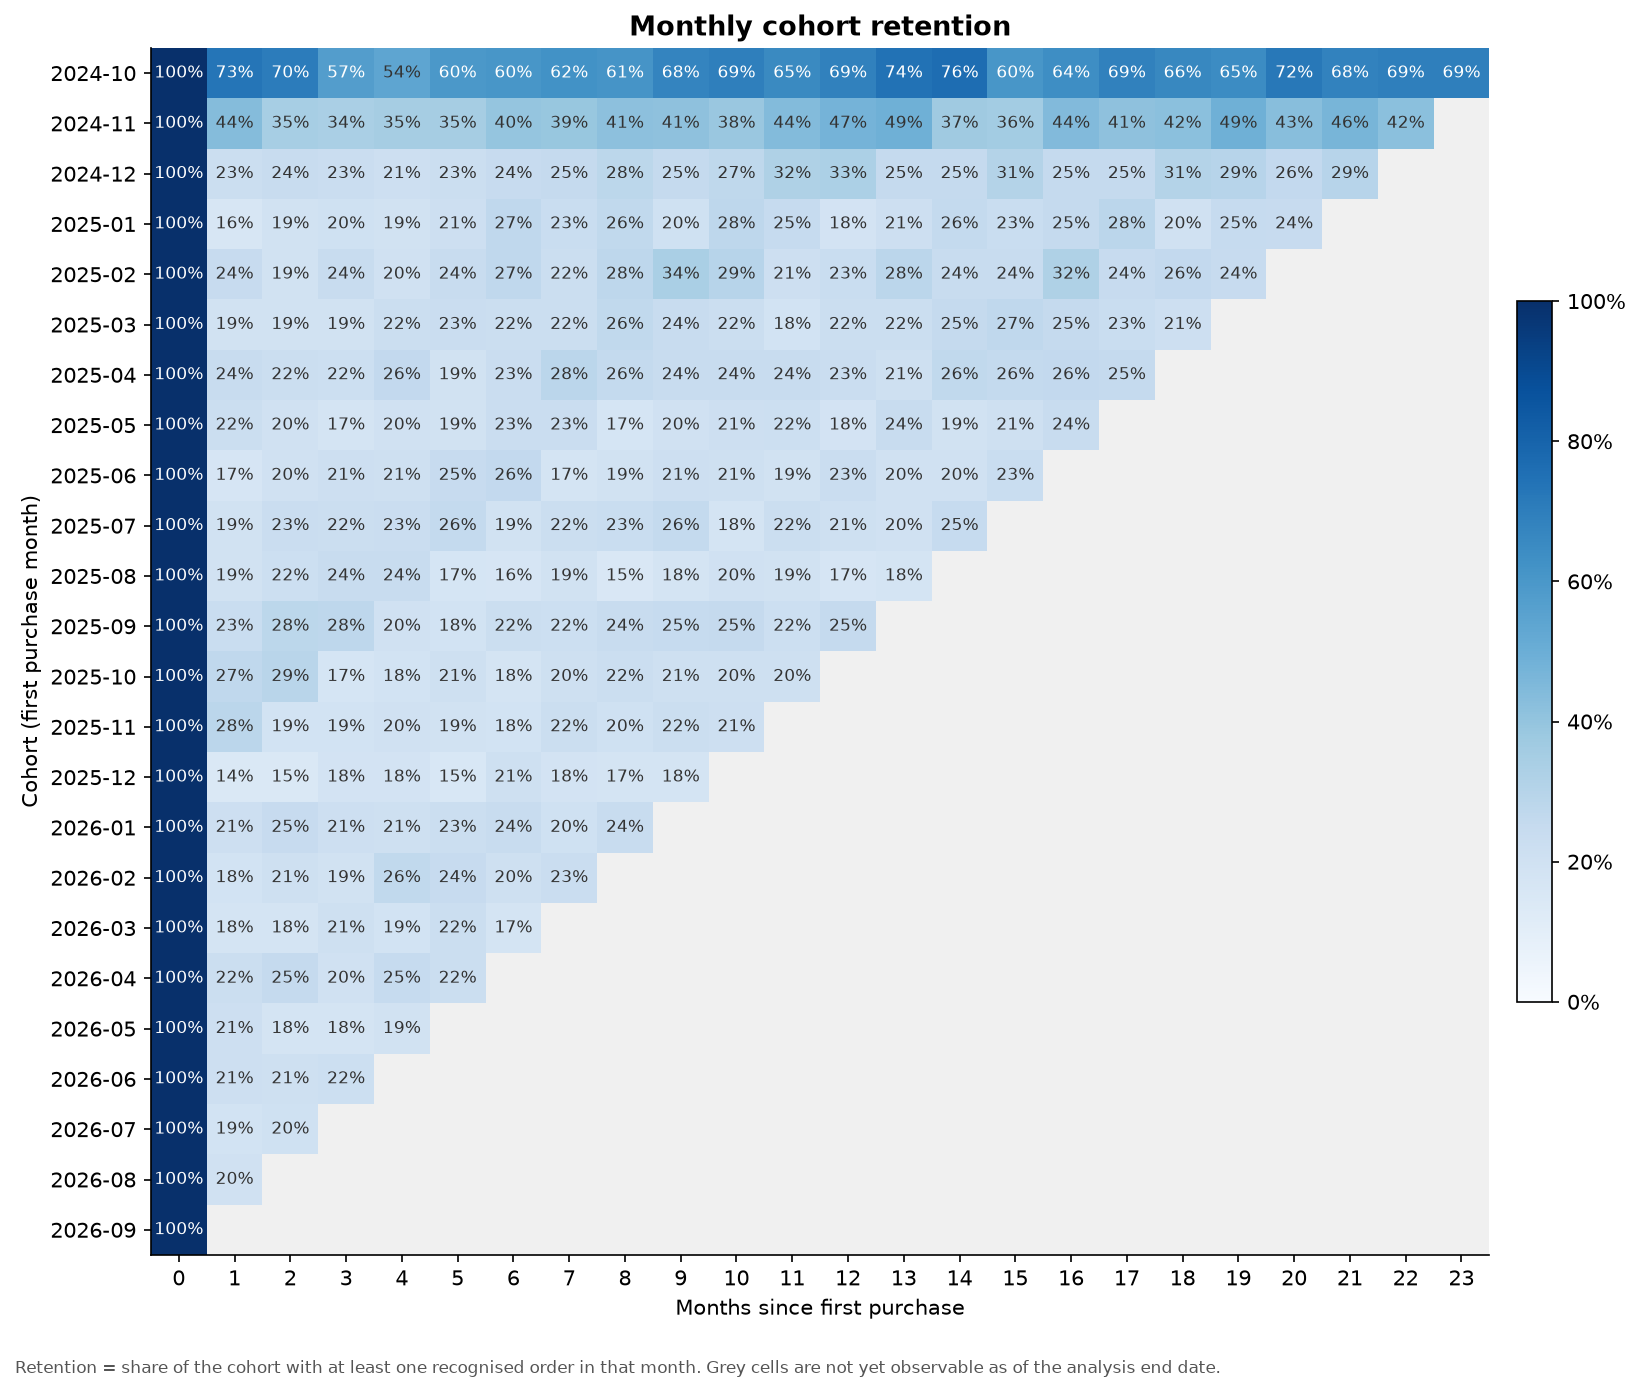

In [5]:
figures = {
    "cohort_retention_heatmap": save_figure(
        plot_cohort_retention_heatmap(cohorts.retention_matrix),
        FIGURE_FILENAMES["cohort_retention_heatmap"],
    ),
    "cohort_sizes": save_figure(
        plot_cohort_sizes(cohorts.sizes), FIGURE_FILENAMES["cohort_sizes"]
    ),
    "cohort_revenue_curve": save_figure(
        plot_cohort_revenue_curve(cohorts.revenue),
        FIGURE_FILENAMES["cohort_revenue_curve"],
    ),
}
display(Image(filename=str(figures["cohort_retention_heatmap"])))

**Which cohorts are largest?** Cohort size determines how much noise a retention rate carries.

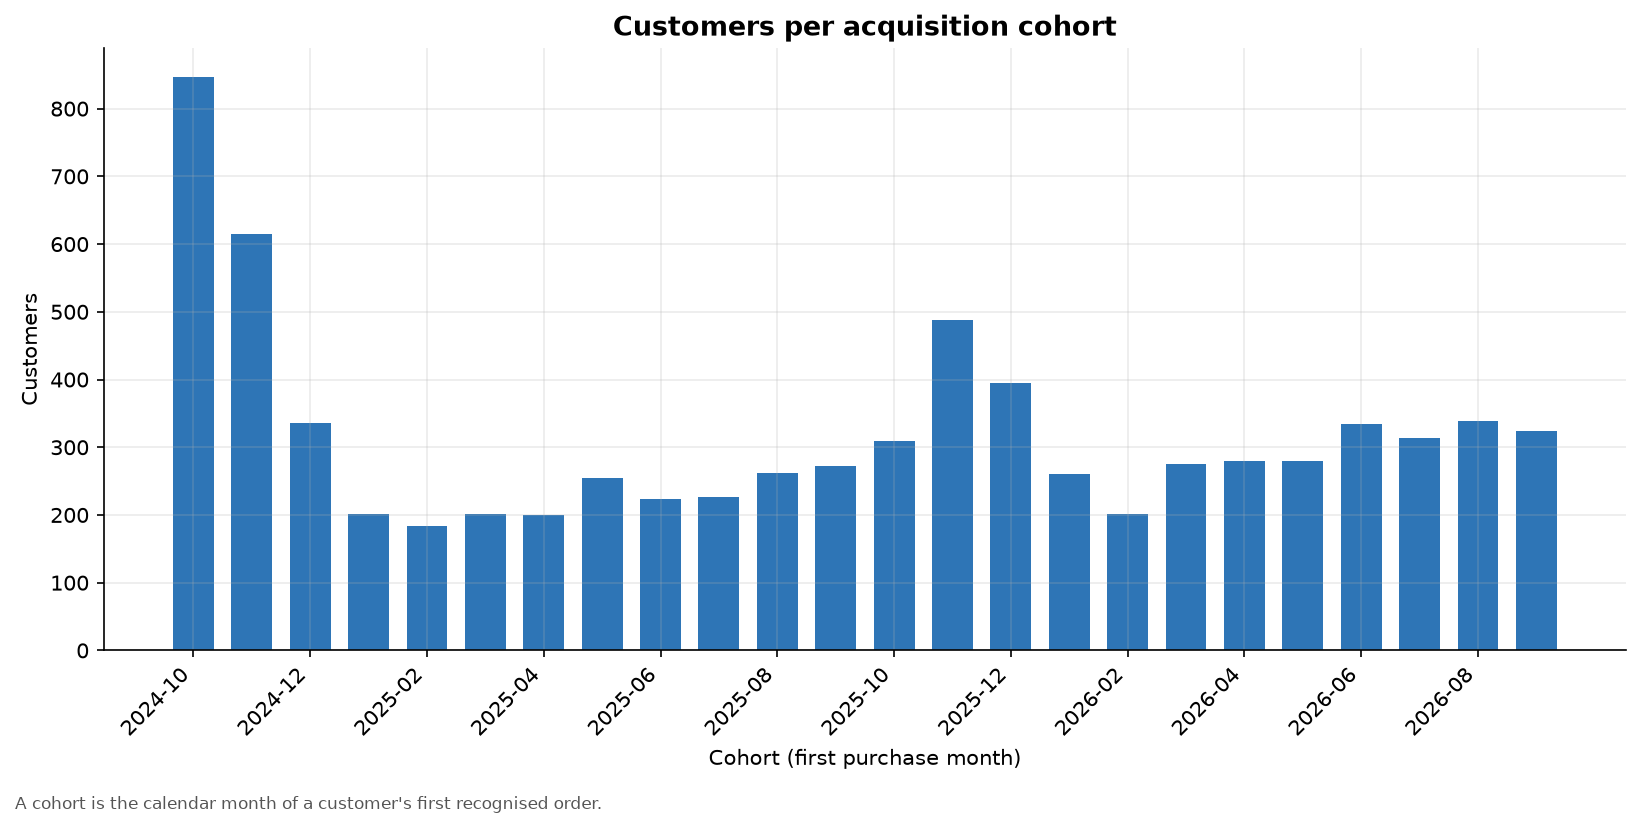

In [6]:
display(Image(filename=str(figures["cohort_sizes"])))

**How much does a cohort customer spend over time?** Revenue per original cohort customer by
month offset, averaged across cohorts.

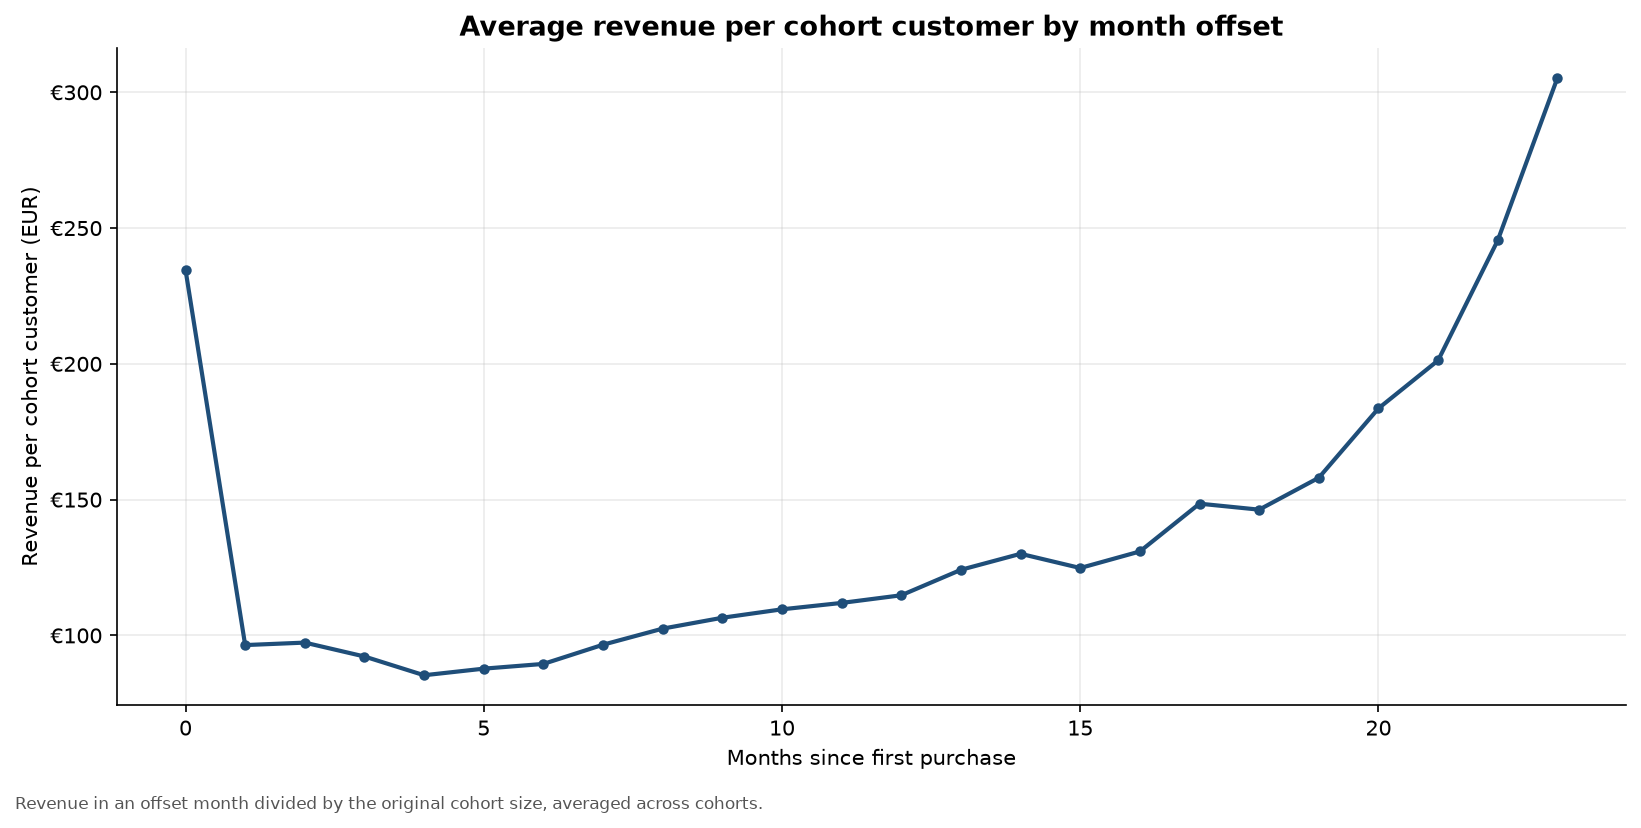

In [7]:
display(Image(filename=str(figures["cohort_revenue_curve"])))

## 4. Caveats

* Later cohorts have fewer observable months, so only compare cohorts at the same offset.
* The most recent cohorts are still within their acquisition month and cannot show month-1
  retention yet.
* A cohort's month-1 retention reflects the behaviour of first-time buyers; it says nothing
  about why they returned.
* Retention here is order-based, not subscription-based: one order counts as retained.